In [ ]:
import yfinance
import pandas as pd
import numpy as np
from pathlib import Path

[ 99 100  99  97  97  99  99 101 102 103 103 104 105 104 106 106 105]


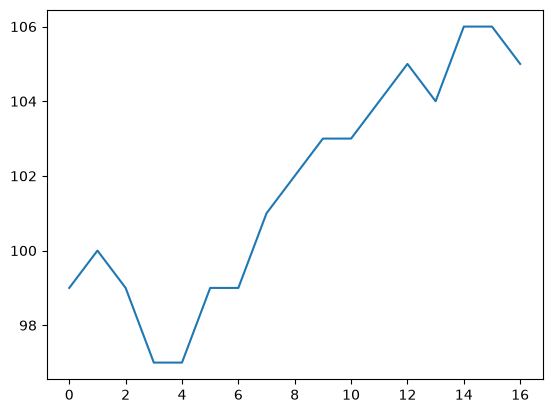

In [62]:
import numpy as np
import matplotlib.pyplot as plt
y = 100 + np.cumsum(np.random.randint(-2,3,17))
print(y)
plt.plot(y)

# RSI manual calculation

In [ ]:
import pandas as pd
closes = pd.Series([99, 97, 99, 101, 100, 101, 102, 104, 
                        106, 105, 105, 105, 106, 106, 104, 103])

# first 14 days
diff = closes.diff()[1:]
print(diff)
diff_14 = diff[:14]
g, l = diff_14.clip(lower=0).sum(), -diff_14.clip(upper=0).sum()
avg_g, avg_l = g/14, l/14
print("G:", g)  # 11
print("L:", l)  # 6
rsi_14 = 100 - 100/(1+avg_g/avg_l)  # 64.70588235294119
print("rsi_14:", rsi_14)

# next day
new_avg_g = (avg_g*13 + 0)/14
new_avg_l = (avg_l*13 + 1)/14
rsi_15 = 100 - 100/(1+new_avg_g/new_avg_l)
print("rsi_15:", rsi_15)  # 60.851063829787236

1    -2.0
2     2.0
3     2.0
4    -1.0
5     1.0
6     1.0
7     2.0
8     2.0
9    -1.0
10    0.0
11    0.0
12    1.0
13    0.0
14   -2.0
15   -1.0
dtype: float64
G: 11.0
L: 6.0
rsi_14: 64.70588235294119
rsi_15: 60.851063829787236


# stoch %K and %D

In [ ]:
import pandas as pd
def mock_ohlcv(n=100, seed=0) -> pd.DataFrame:
    """Make a mock valid OHLCV, of `n` days, with rng `seed`"""
    rng = np.random.default_rng(seed)

    # simulate close wandering around 100
    close_price = 100 + np.cumsum(rng.integers(-2, 3, n))  
    open_price = close_price + rng.integers(-2, 3, n)

    # so that high >= open or close, and low <= open or close
    high = np.maximum(open_price, close_price) + rng.integers(0, 2, n)
    low = np.minimum(open_price, close_price) - rng.integers(0, 2, n)
    

    return pd.DataFrame({
        "High": high,
        "Low": low,
        "Close": close_price, 
    }) 

df = mock_ohlcv(n=16, seed=88)
# print(data)

# 14th day:
k_14 = (df["Close"].iloc[13] - df["Low"].iloc[:14].min())/(
    df["High"].iloc[:14].max() - df["Low"].iloc[:14].min())

k_15 = (df["Close"].iloc[14] - df["Low"].iloc[1:15].min())/(
    df["High"].iloc[1:15].max() - df["Low"].iloc[1:15].min())

k_16 = (df["Close"].iloc[15] - df["Low"].iloc[2:16].min())/(
    df["High"].iloc[2:16].max()- df["Low"].iloc[2:16].min())

d_16 = (k_14 + k_15 + k_16) / 3
print("k_14/15/16:", k_14, k_15, k_16)
print("d_16:", d_16)

# h = 109, l= 98, c = 105
print((105-98)/(109-98))
# c = 105
print((106-98)/(109-98))
# c = 105 
print((105-99)/(109-99))

print((0.6363636363636364+0.7272727272727273+0.6)/3)
# stoch_k and _d returns percentage so *100 before using it

print(df["Close"].to_numpy())
print(df["High"].to_numpy())
print(df["Low"].to_numpy())

k_14/15/16: 0.6363636363636364 0.7272727272727273 0.6
d_16: 0.6545454545454547
0.6363636363636364
0.7272727272727273
0.6
0.6545454545454547
[100  99 101 102 103 104 106 107 107 108 108 106 107 105 106 105]
[100 100 103 103 104 105 106 108 107 109 108 107 109 107 107 106]
[ 99  98 101  99 103 103 104 107 106 107 107 105 106 105 106 103]


# Aroon up and down

High: 101, 100, 103, 104, 103, 104, 109, 107, 107, 109, 110, 106, 108, 106, 106, 105, 107, 106, 107, 104, 107, 106, 104, 105, 106, 105, 103
Low: 99, 99, 100, 102, 102, 102, 105, 104, 107, 107, 107, 105, 105, 102, 105, 103, 104, 103, 104, 103, 105, 104, 101, 101, 102, 102, 102
14 23
15 24
16 24
(np.float64(41.666666666666664), np.float64(4.166666666666667)) (np.float64(37.5), np.float64(0.0)) (np.float64(33.333333333333336), np.float64(0.0))


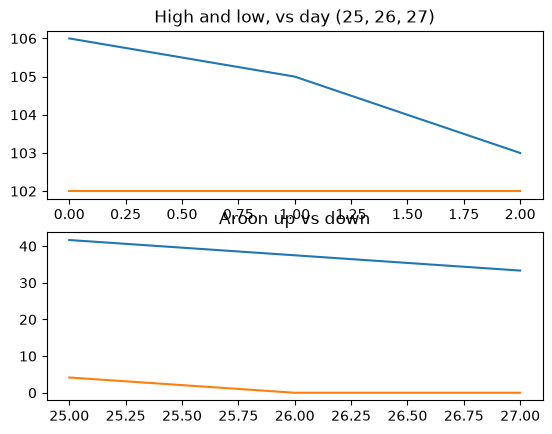

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
def mock_ohlcv(n=100, seed=0) -> pd.DataFrame:
    """Make a mock valid OHLCV, of `n` days, with rng `seed`"""
    rng = np.random.default_rng(seed)

    # simulate close wandering around 100
    close_price = 100 + np.cumsum(rng.integers(-2, 3, n))  
    open_price = close_price + rng.integers(-2, 3, n)

    # so that high >= open or close, and low <= open or close
    high = np.maximum(open_price, close_price) + rng.integers(0, 2, n)
    low = np.minimum(open_price, close_price) - rng.integers(0, 2, n)
    

    return pd.DataFrame({
        "High": high,
        "Low": low
    }) 

df = mock_ohlcv(n=27, seed=88)
high, low = df["High"], df["Low"]
print("High:", ", ".join(map(str, df["High"].to_numpy())))
print("Low:", ", ".join(map(str, df["Low"].to_numpy())))

# 25th day (24th index)
h_25 = np.argmax(high[:25][::-1])
l_25 = np.argmin(low[:25][::-1])
print(h_25, l_25)

ar = lambda x: 100*(24-x)/24
aroon_25 = (ar(h_25), ar(l_25))

# 26th day (25th index)
h_26 = np.argmax(high[1:26][::-1])
l_26 = np.argmin(low[1:26][::-1])
print(h_26, l_26)

aroon_26 = (ar(h_26), ar(l_26))

# 27th day (26th index, last)
h_27 = np.argmax(high[2:27][::-1])
l_27 = np.argmin(low[2:27][::-1])
print(h_27, l_27)

aroon_27 = (ar(h_27), ar(l_27))

print(aroon_25, aroon_26, aroon_27)


# plt.plot(high)
# plt.plot(low)
fig, ax = plt.subplots(2,1)

ax[0].set_title("High and low, vs day (25, 26, 27)")
ax[0].plot(df["High"].to_numpy()[-3:])
ax[0].plot(df["Low"].to_numpy()[-3:])

ax[1].set_title("Aroon up vs down")
ax[1].plot([25,26,27], [aroon_25[0],aroon_26[0], aroon_27[0]] )
ax[1].plot([25,26,27], [aroon_25[1],aroon_26[1], aroon_27[1]])

In [ ]:
import numpy as np
import pandas as pd
from pathlib import Path
from sklearn.model_selection import TimeSeriesSplit

PROCESSED_PATH = Path(__file__).parent.parent.parent / "data" / "processed" / "processed.csv"



def walk_forward_splits(df: pd.DataFrame, n_split: int = 5, gap: int = 25
                        ) -> list[tuple[pd.Index, pd.Index]]:

    tss = TimeSeriesSplit(n_splits=n_split, gap=gap)

    dates: pd.Series = pd.to_datetime(
        np.sort(pd.to_datetime(df["Date"]).unique()))

    splits: list[tuple[pd.Index, pd.Index]] = []

    for train_date_idx, test_date_idx in tss.split(dates):
        # find the dates corresponding to the index
        train_dates = dates[train_date_idx]
        test_dates = dates[test_date_idx]

        assert test_dates[0] > train_dates[-1]  # passed

        # find all the indexes corresponding to the dates
        train_mask = df["Date"].isin(train_dates)
        test_mask = df["Date"].isin(test_dates)
        splits.append(
            (df.index[train_mask],
            df.index[test_mask])
        )
        # assert df.loc[train_date_idx, "Date"].max() < df.loc[test_date_idx, "Date"].min()
        print("TRAIN END:", train_dates[-1])
        print("TEST START:", test_dates[0])

        print("dates between that:")
        print(dates[train_date_idx[-1] + 1 : test_date_idx[0]])
        # print(df.loc[train_date_idx[-1], "Date"])
        # print(df.loc[test_date_idx[0], "Date"])
        # print("Old print statement:", df.loc[test_date_idx, "Date"].min() - df.loc[train_date_idx, "Date"].max())
        # print(f"""fold: train ends {train_dates[-1].date()}, 
                # test starts {test_dates[0].date()}, 
                # gap = {len(pd.bdate_range(train_dates[-1], test_dates[0])) - 1} bdays""")
        

    return splits



df: pd.DataFrame = pd.read_csv(PROCESSED_PATH, parse_dates=["Date"])

df = df.sort_values("Date").reset_index(drop=True)  # simply easier to see whats going on

s = walk_forward_splits(df)

for i, (train_idx, test_idx) in enumerate(s):
    continue
    print(f"split {i}: ")
    print(f"train_idx: {train_idx[0]} to {train_idx[-1]}, {len(train_idx)} items")
    print(f"test_idx: {test_idx[0]} to {test_idx[-1]}, {len(test_idx)} items")
    print()



Whole day spent on one variable misname:
- The (train, test) index was meant for date series, not df, and you cant do df.loc[test_idx, "Date"], because test_idx is meant for date series, which is litearlly just dates sorted in chronological order (from `tss.split(dates)`), and not raw df, which has different dates at test_idx depending on how its sorted.  

- the print statement prints exactly 25 dates. Looks like there are always a few days they skipped, more than just weekends. So pd business day range function was wrong, it was just a simple mon-friday calender.

- Then, the indexes may matter if for whatever reason df passes starting row index not at 0. Meaning, .iloc[] wont work. So, maybe do something with `flatnonzero()` just to be safe, so that when looking up dates its consistient